# Step 1 Import Libaries and Load all five datasets

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Folder containing the CSV files
#data_path = Path(r"C:\Users\kanch\Documents\datascience-thesis\data\raw\promise_source")
# The notebook lives in notebooks/, so the project folder is one level up
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data_path = ROOT / "data" / "raw" / "promise_source"
print("Project folder:", ROOT)



## Load Data Set

In [2]:
cm1 = pd.read_csv(data_path / "cm1.csv")
jm1 = pd.read_csv(data_path / "jm1.csv")
kc1 = pd.read_csv(data_path / "kc1.csv")
kc2 = pd.read_csv(data_path / "kc2.csv")
pc1 = pd.read_csv(data_path / "pc1.csv")

## Store all datasets in a dictionary

In [3]:
datasets = {
    "CM1": cm1,
    "JM1": jm1,
    "KC1": kc1,
    "KC2": kc2,
    "PC1": pc1
}

In [4]:
# Check that all datasets loaded correctly

In [5]:
print("All datasets loaded successfully!")
print()

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} rows × {df.shape[1]} columns")

All datasets loaded successfully!

CM1: 498 rows × 22 columns
JM1: 13204 rows × 22 columns
KC1: 2109 rows × 22 columns
KC2: 522 rows × 22 columns
PC1: 1109 rows × 22 columns


# Step 2 Check dataset structure

## Initial Data Quality assessment

In [6]:
for name, df in datasets.items():
    print("=" * 70)
    print(f"DATASET: {name}")
    print("=" * 70)

    print(f"Number of rows    : {df.shape[0]}")
    print(f"Number of columns : {df.shape[1]}")

    print("\nColumn Names:")
    print(df.columns.tolist())

    print("\nData Types:")
    print(df.dtypes)

    print("\nFirst 5 Rows:")
    display(df.head())

    print("\n")

DATASET: CM1
Number of rows    : 498
Number of columns : 22

Column Names:
['loc', 'v(g)', 'ev(g)', 'iv(g)', 'n', 'v', 'l', 'd', 'i', 'e', 'b', 't', 'lOCode', 'lOComment', 'lOBlank', 'locCodeAndComment', 'uniq_Op', 'uniq_Opnd', 'total_Op', 'total_Opnd', 'branchCount', 'defects']

Data Types:
loc                  float64
v(g)                 float64
ev(g)                float64
iv(g)                float64
n                    float64
v                    float64
l                    float64
d                    float64
i                    float64
e                    float64
b                    float64
t                    float64
lOCode                 int64
lOComment              int64
lOBlank                int64
locCodeAndComment      int64
uniq_Op              float64
uniq_Opnd            float64
total_Op             float64
total_Opnd           float64
branchCount          float64
defects                 bool
dtype: object

First 5 Rows:


,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,...,lOCode,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,defects
0,1.1,1.4,1.4,1.4,1.3,1.30,1.30,1.30,1.30,1.30,...,2,2,2,2,1.2,1.2,1.2,1.2,1.4,False
1,1.0,1.0,1.0,1.0,1.0,1.00,1.00,1.00,1.00,1.00,...,1,1,1,1,1.0,1.0,1.0,1.0,1.0,True
2,24.0,5.0,1.0,3.0,63.0,309.13,0.11,9.50,32.54,2936.77,...,1,0,6,0,15.0,15.0,44.0,19.0,9.0,False
3,20.0,4.0,4.0,2.0,47.0,215.49,0.06,16.00,13.47,3447.89,...,0,0,3,0,16.0,8.0,31.0,16.0,7.0,False
4,24.0,6.0,6.0,2.0,72.0,346.13,0.06,17.33,19.97,5999.58,...,0,0,3,0,16.0,12.0,46.0,26.0,11.0,False




DATASET: JM1
Number of rows    : 13204
Number of columns : 22

Column Names:
['loc', 'v(g)', 'ev(g)', 'iv(g)', 'n', 'v', 'l', 'd', 'i', 'e', 'b', 't', 'lOCode', 'lOComment', 'lOBlank', 'locCodeAndComment', 'uniq_Op', 'uniq_Opnd', 'total_Op', 'total_Opnd', 'branchCount', 'defects']

Data Types:
loc                  float64
v(g)                 float64
ev(g)                float64
iv(g)                float64
n                    float64
v                    float64
l                    float64
d                    float64
i                    float64
e                    float64
b                    float64
t                    float64
lOCode                 int64
lOComment              int64
lOBlank                int64
locCodeAndComment      int64
uniq_Op              float64
uniq_Opnd            float64
total_Op             float64
total_Opnd           float64
branchCount          float64
defects                 bool
dtype: object

First 5 Rows:


,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,...,lOCode,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,defects
0,1.1,1.4,1.4,1.4,1.3,1.30,1.30,1.30,1.30,1.30,...,2,2,2,2,1.2,1.2,1.2,1.2,1.4,False
1,1.0,1.0,1.0,1.0,1.0,1.00,1.00,1.00,1.00,1.00,...,1,1,1,1,1.0,1.0,1.0,1.0,1.0,True
2,72.0,7.0,1.0,6.0,198.0,1134.13,0.05,20.31,55.85,23029.10,...,51,10,8,1,17.0,36.0,112.0,86.0,13.0,True
3,190.0,3.0,1.0,3.0,600.0,4348.76,0.06,17.06,254.87,74202.67,...,129,29,28,2,17.0,135.0,329.0,271.0,5.0,True
4,37.0,4.0,1.0,4.0,126.0,599.12,0.06,17.19,34.86,10297.30,...,28,1,6,0,11.0,16.0,76.0,50.0,7.0,True




DATASET: KC1
Number of rows    : 2109
Number of columns : 22

Column Names:
['loc', 'v(g)', 'ev(g)', 'iv(g)', 'n', 'v', 'l', 'd', 'i', 'e', 'b', 't', 'lOCode', 'lOComment', 'lOBlank', 'locCodeAndComment', 'uniq_Op', 'uniq_Opnd', 'total_Op', 'total_Opnd', 'branchCount', 'defects']

Data Types:
loc                  float64
v(g)                 float64
ev(g)                float64
iv(g)                float64
n                    float64
v                    float64
l                    float64
d                    float64
i                    float64
e                    float64
b                    float64
t                    float64
lOCode                 int64
lOComment              int64
lOBlank                int64
locCodeAndComment      int64
uniq_Op              float64
uniq_Opnd            float64
total_Op             float64
total_Opnd           float64
branchCount          float64
defects                 bool
dtype: object

First 5 Rows:


,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,...,lOCode,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,defects
0,1.1,1.4,1.4,1.4,1.3,1.30,1.30,1.30,1.30,1.30,...,2,2,2,2,1.2,1.2,1.2,1.2,1.4,False
1,1.0,1.0,1.0,1.0,1.0,1.00,1.00,1.00,1.00,1.00,...,1,1,1,1,1.0,1.0,1.0,1.0,1.0,True
2,83.0,11.0,1.0,11.0,171.0,927.89,0.04,23.04,40.27,21378.61,...,65,10,6,0,18.0,25.0,107.0,64.0,21.0,True
3,46.0,8.0,6.0,8.0,141.0,769.78,0.07,14.86,51.81,11436.73,...,37,2,5,0,16.0,28.0,89.0,52.0,15.0,True
4,25.0,3.0,1.0,3.0,58.0,254.75,0.11,9.35,27.25,2381.95,...,21,0,2,0,11.0,10.0,41.0,17.0,5.0,True




DATASET: KC2
Number of rows    : 522
Number of columns : 22

Column Names:
['loc', 'v(g)', 'ev(g)', 'iv(g)', 'n', 'v', 'l', 'd', 'i', 'e', 'b', 't', 'lOCode', 'lOComment', 'lOBlank', 'lOCodeAndComment', 'uniq_Op', 'uniq_Opnd', 'total_Op', 'total_Opnd', 'branchCount', 'problems']

Data Types:
loc                 float64
v(g)                float64
ev(g)               float64
iv(g)               float64
n                   float64
v                   float64
l                   float64
d                   float64
i                   float64
e                   float64
b                   float64
t                   float64
lOCode                int64
lOComment             int64
lOBlank               int64
lOCodeAndComment      int64
uniq_Op             float64
uniq_Opnd           float64
total_Op            float64
total_Opnd          float64
branchCount         float64
problems                str
dtype: object

First 5 Rows:


,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,...,lOCode,lOComment,lOBlank,lOCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,problems
0,1.1,1.4,1.4,1.4,1.3,1.30,1.30,1.30,1.30,1.30,...,2,2,2,2,1.2,1.2,1.2,1.2,1.4,no
1,1.0,1.0,1.0,1.0,1.0,1.00,1.00,1.00,1.00,1.00,...,1,1,1,1,1.0,1.0,1.0,1.0,1.0,yes
2,415.0,59.0,50.0,51.0,1159.0,8411.31,0.01,103.53,81.24,870848.58,...,359,35,9,10,47.0,106.0,692.0,467.0,106.0,yes
3,230.0,33.0,10.0,16.0,575.0,3732.82,0.03,39.82,93.74,148644.06,...,174,15,34,5,23.0,67.0,343.0,232.0,65.0,yes
4,175.0,26.0,12.0,13.0,500.0,3123.96,0.03,29.48,105.96,92103.07,...,142,7,19,4,18.0,58.0,310.0,190.0,51.0,yes




DATASET: PC1
Number of rows    : 1109
Number of columns : 22

Column Names:
['loc', 'v(g)', 'ev(g)', 'iv(G)', 'N', 'V', 'L', 'D', 'I', 'E', 'B', 'T', 'lOCode', 'lOComment', 'locCodeAndComment', 'lOBlank', 'uniq_Op', 'uniq_Opnd', 'total_Op', 'total_Opnd', 'branchCount', 'defects']

Data Types:
loc                  float64
v(g)                 float64
ev(g)                float64
iv(G)                float64
N                    float64
V                    float64
L                    float64
D                    float64
I                    float64
E                    float64
B                    float64
T                    float64
lOCode                 int64
lOComment              int64
locCodeAndComment      int64
lOBlank                int64
uniq_Op              float64
uniq_Opnd            float64
total_Op             float64
total_Opnd           float64
branchCount          float64
defects                 bool
dtype: object

First 5 Rows:


,loc,v(g),ev(g),iv(G),N,V,L,D,I,E,...,lOCode,lOComment,locCodeAndComment,lOBlank,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,defects
0,1.1,1.4,1.4,1.4,1.3,1.30,1.30,1.30,1.30,1.30,...,2,2,2,2,1.2,1.2,1.2,1.2,1.4,False
1,1.0,1.0,1.0,1.0,1.0,1.00,1.00,1.00,1.00,1.00,...,1,1,1,1,1.0,1.0,1.0,1.0,1.0,True
2,91.0,9.0,3.0,2.0,318.0,2089.21,0.04,27.68,75.47,57833.24,...,80,44,11,31,29.0,66.0,192.0,126.0,17.0,True
3,109.0,21.0,5.0,18.0,381.0,2547.56,0.04,28.37,89.79,72282.68,...,97,41,12,24,28.0,75.0,229.0,152.0,38.0,True
4,505.0,106.0,41.0,82.0,2339.0,20696.93,0.01,75.93,272.58,1571506.88,...,457,71,48,49,64.0,397.0,1397.0,942.0,178.0,True


# Step 3 Check missing values

In [7]:
print("MISSING VALUE ANALYSIS")
print("=" * 70)

for name, df in datasets.items():

    total_missing = df.isnull().sum().sum()

    print(f"\n{name}")
    print("-" * 40)
    print(f"Total missing values: {total_missing}")

    missing_by_column = df.isnull().sum()
    missing_by_column = missing_by_column[missing_by_column > 0]

    if len(missing_by_column) > 0:
        print("\nMissing values by column:")
        print(missing_by_column)
    else:
        print("No missing values found.")

MISSING VALUE ANALYSIS

CM1
----------------------------------------
Total missing values: 0
No missing values found.

JM1
----------------------------------------
Total missing values: 0
No missing values found.

KC1
----------------------------------------
Total missing values: 0
No missing values found.

KC2
----------------------------------------
Total missing values: 0
No missing values found.

PC1
----------------------------------------
Total missing values: 0
No missing values found.


# Step 4 — Check duplicates

In [8]:
print("DUPLICATE ANALYSIS")
print("=" * 70)

duplicate_summary = []

for name, df in datasets.items():

    duplicate_count = df.duplicated().sum()
    duplicate_percentage = (duplicate_count / len(df)) * 100

    duplicate_summary.append({
        "Dataset": name,
        "Total Rows": len(df),
        "Duplicate Rows": duplicate_count,
        "Duplicate Percentage": round(duplicate_percentage, 2)
    })

duplicate_summary = pd.DataFrame(duplicate_summary)

display(duplicate_summary)

DUPLICATE ANALYSIS


,Dataset,Total Rows,Duplicate Rows,Duplicate Percentage
0,CM1,498,56,11.24
1,JM1,13204,4296,32.54
2,KC1,2109,897,42.53
3,KC2,522,147,28.16
4,PC1,1109,155,13.98


#Step 5 — Create a backup before cleaning

In [9]:
original_datasets = {
    name: df.copy()
    for name, df in datasets.items()
}

print("Backup of original datasets created successfully.")

Backup of original datasets created successfully.


# Step 6 — Remove exact duplicate rows

In [10]:
duplicate_removal_summary = []

for name, df in datasets.items():

    rows_before = len(df)

    # Remove exact duplicate rows
    datasets[name] = df.drop_duplicates().reset_index(drop=True)

    rows_after = len(datasets[name])

    rows_removed = rows_before - rows_after

    duplicate_removal_summary.append({
        "Dataset": name,
        "Rows Before": rows_before,
        "Duplicates Removed": rows_removed,
        "Rows After": rows_after
    })

duplicate_removal_summary = pd.DataFrame(
    duplicate_removal_summary
)

display(duplicate_removal_summary)

,Dataset,Rows Before,Duplicates Removed,Rows After
0,CM1,498,56,442
1,JM1,13204,4296,8908
2,KC1,2109,897,1212
3,KC2,522,147,375
4,PC1,1109,155,954


# Step 7 — Verify duplicates are gone

In [11]:
print("DUPLICATE CHECK AFTER CLEANING")
print("=" * 50)

for name, df in datasets.items():

    duplicate_count = df.duplicated().sum()

    print(
        f"{name}: {duplicate_count} "
        f"duplicate rows remaining"
)

DUPLICATE CHECK AFTER CLEANING
CM1: 0 duplicate rows remaining
JM1: 0 duplicate rows remaining
KC1: 0 duplicate rows remaining
KC2: 0 duplicate rows remaining
PC1: 0 duplicate rows remaining


# Step 8 — Compare column names

## Check coloumn name accross the data set

In [12]:
for name, df in datasets.items():
    print("=" * 70)
    print(f"{name} COLUMN NAMES")
    print("=" * 70)

    print(df.columns.tolist())
    print()

CM1 COLUMN NAMES
['loc', 'v(g)', 'ev(g)', 'iv(g)', 'n', 'v', 'l', 'd', 'i', 'e', 'b', 't', 'lOCode', 'lOComment', 'lOBlank', 'locCodeAndComment', 'uniq_Op', 'uniq_Opnd', 'total_Op', 'total_Opnd', 'branchCount', 'defects']

JM1 COLUMN NAMES
['loc', 'v(g)', 'ev(g)', 'iv(g)', 'n', 'v', 'l', 'd', 'i', 'e', 'b', 't', 'lOCode', 'lOComment', 'lOBlank', 'locCodeAndComment', 'uniq_Op', 'uniq_Opnd', 'total_Op', 'total_Opnd', 'branchCount', 'defects']

KC1 COLUMN NAMES
['loc', 'v(g)', 'ev(g)', 'iv(g)', 'n', 'v', 'l', 'd', 'i', 'e', 'b', 't', 'lOCode', 'lOComment', 'lOBlank', 'locCodeAndComment', 'uniq_Op', 'uniq_Opnd', 'total_Op', 'total_Opnd', 'branchCount', 'defects']

KC2 COLUMN NAMES
['loc', 'v(g)', 'ev(g)', 'iv(g)', 'n', 'v', 'l', 'd', 'i', 'e', 'b', 't', 'lOCode', 'lOComment', 'lOBlank', 'lOCodeAndComment', 'uniq_Op', 'uniq_Opnd', 'total_Op', 'total_Opnd', 'branchCount', 'problems']

PC1 COLUMN NAMES
['loc', 'v(g)', 'ev(g)', 'iv(G)', 'N', 'V', 'L', 'D', 'I', 'E', 'B', 'T', 'lOCode', 'lOComm

# Step 9 — Standardise column names

In [13]:
rename_columns = {
    "iv(G)": "iv(g)",
    "N": "n",
    "V": "v",
    "L": "l",
    "D": "d",
    "I": "i",
    "E": "e",
    "B": "b",
    "T": "t",
    "lOCodeAndComment": "locCodeAndComment"
}

for name in datasets:
    datasets[name] = datasets[name].rename(
        columns=rename_columns
    )

print("Column names standardised successfully.")

Column names standardised successfully.


In [14]:
for name, df in datasets.items():
    print(f"{name}:")
    print(df.columns.tolist())
    print()

CM1:
['loc', 'v(g)', 'ev(g)', 'iv(g)', 'n', 'v', 'l', 'd', 'i', 'e', 'b', 't', 'lOCode', 'lOComment', 'lOBlank', 'locCodeAndComment', 'uniq_Op', 'uniq_Opnd', 'total_Op', 'total_Opnd', 'branchCount', 'defects']

JM1:
['loc', 'v(g)', 'ev(g)', 'iv(g)', 'n', 'v', 'l', 'd', 'i', 'e', 'b', 't', 'lOCode', 'lOComment', 'lOBlank', 'locCodeAndComment', 'uniq_Op', 'uniq_Opnd', 'total_Op', 'total_Opnd', 'branchCount', 'defects']

KC1:
['loc', 'v(g)', 'ev(g)', 'iv(g)', 'n', 'v', 'l', 'd', 'i', 'e', 'b', 't', 'lOCode', 'lOComment', 'lOBlank', 'locCodeAndComment', 'uniq_Op', 'uniq_Opnd', 'total_Op', 'total_Opnd', 'branchCount', 'defects']

KC2:
['loc', 'v(g)', 'ev(g)', 'iv(g)', 'n', 'v', 'l', 'd', 'i', 'e', 'b', 't', 'lOCode', 'lOComment', 'lOBlank', 'locCodeAndComment', 'uniq_Op', 'uniq_Opnd', 'total_Op', 'total_Opnd', 'branchCount', 'problems']

PC1:
['loc', 'v(g)', 'ev(g)', 'iv(g)', 'n', 'v', 'l', 'd', 'i', 'e', 'b', 't', 'lOCode', 'lOComment', 'locCodeAndComment', 'lOBlank', 'uniq_Op', 'uniq_Opnd

# Step 10 — Check the target variable

In [15]:
for name, df in datasets.items():

    print("=" * 50)
    print(name)

    if "defects" in df.columns:
        print("Target column: defects")
        print(df["defects"].value_counts(dropna=False))

    elif "problems" in df.columns:
        print("Target column: problems")
        print(df["problems"].value_counts(dropna=False))

    else:
        print("WARNING: Target column not found!")

    print()

CM1
Target column: defects
defects
False    394
True      48
Name: count, dtype: int64

JM1
Target column: defects
defects
False    6904
True     2004
Name: count, dtype: int64

KC1
Target column: defects
defects
False    897
True     315
Name: count, dtype: int64

KC2
Target column: problems
problems
no     270
yes    105
Name: count, dtype: int64

PC1
Target column: defects
defects
False    884
True      70
Name: count, dtype: int64



# Step 11 — Convert KC2 target to match the others

In [16]:
if "problems" in datasets["KC2"].columns:

    # Clean text first
    datasets["KC2"]["problems"] = (
        datasets["KC2"]["problems"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    # Convert yes/no to True/False
    datasets["KC2"]["defects"] = (
        datasets["KC2"]["problems"].map({
            "yes": True,
            "no": False
        })
    )

    # Remove old problems column
    datasets["KC2"] = datasets["KC2"].drop(
        columns=["problems"]
    )

print("KC2 target variable standardised.")

KC2 target variable standardised.


# Step 12 — Verify the target variables

In [17]:
for name, df in datasets.items():

    print("=" * 50)
    print(f"{name} - DEFECT DISTRIBUTION")
    print("=" * 50)

    print(df["defects"].value_counts(dropna=False))

    print("\nPercentage:")
    print(
        df["defects"]
        .value_counts(normalize=True, dropna=False)
        .mul(100)
        .round(2)
    )
   

CM1 - DEFECT DISTRIBUTION
defects
False    394
True      48
Name: count, dtype: int64

Percentage:
defects
False    89.14
True     10.86
Name: proportion, dtype: float64
JM1 - DEFECT DISTRIBUTION
defects
False    6904
True     2004
Name: count, dtype: int64

Percentage:
defects
False    77.5
True     22.5
Name: proportion, dtype: float64
KC1 - DEFECT DISTRIBUTION
defects
False    897
True     315
Name: count, dtype: int64

Percentage:
defects
False    74.01
True     25.99
Name: proportion, dtype: float64
KC2 - DEFECT DISTRIBUTION
defects
False    270
True     105
Name: count, dtype: int64

Percentage:
defects
False    72.0
True     28.0
Name: proportion, dtype: float64
PC1 - DEFECT DISTRIBUTION
defects
False    884
True      70
Name: count, dtype: int64

Percentage:
defects
False    92.66
True      7.34
Name: proportion, dtype: float64


# Step 13 — Verify all datasets have consistent columns

In [18]:
reference_columns = set(datasets["CM1"].columns)

for name, df in datasets.items():

    current_columns = set(df.columns)

    print(f"\n{name}")

    if current_columns == reference_columns:
        print("✓ Columns are consistent with CM1")
    else:
        print("✗ Column differences found")

        print(
            "Missing:",
            reference_columns - current_columns
        )

        print(
            "Extra:",
            current_columns - reference_columns
        )


CM1
✓ Columns are consistent with CM1

JM1
✓ Columns are consistent with CM1

KC1
✓ Columns are consistent with CM1

KC2
✓ Columns are consistent with CM1

PC1
✓ Columns are consistent with CM1


# Step 14 — Check data types

In [19]:
for name, df in datasets.items():

    print("=" * 60)
    print(f"{name} - DATA TYPES")
    print("=" * 60)

    print(df.dtypes)
    print()

CM1 - DATA TYPES
loc                  float64
v(g)                 float64
ev(g)                float64
iv(g)                float64
n                    float64
v                    float64
l                    float64
d                    float64
i                    float64
e                    float64
b                    float64
t                    float64
lOCode                 int64
lOComment              int64
lOBlank                int64
locCodeAndComment      int64
uniq_Op              float64
uniq_Opnd            float64
total_Op             float64
total_Opnd           float64
branchCount          float64
defects                 bool
dtype: object

JM1 - DATA TYPES
loc                  float64
v(g)                 float64
ev(g)                float64
iv(g)                float64
n                    float64
v                    float64
l                    float64
d                    float64
i                    float64
e                    float64
b                    fl

In [20]:
for name, df in datasets.items():

    predictor_data = df.drop(columns=["defects"])

    non_numeric = predictor_data.select_dtypes(
        exclude=np.number
    ).columns.tolist()

    print(f"{name}: {non_numeric}")

CM1: []
JM1: []
KC1: []
KC2: []
PC1: []


# Step 15 — Check for infinite values

In [21]:
for name, df in datasets.items():

    numeric_cols = df.select_dtypes(include=np.number).columns

    inf_count = np.isinf(df[numeric_cols]).sum().sum()

    print(f"{name}: {inf_count} infinite values")

CM1: 0 infinite values
JM1: 0 infinite values
KC1: 0 infinite values
KC2: 0 infinite values
PC1: 0 infinite values


# Step 16 — Check negative values

In [22]:
for name, df in datasets.items():

    numeric_cols = df.select_dtypes(include=np.number).columns

    negative_counts = (df[numeric_cols] < 0).sum()

    negative_counts = negative_counts[
        negative_counts > 0
    ]

    print("=" * 60)
    print(f"{name} - NEGATIVE VALUES")
    print("=" * 60)

    if len(negative_counts) == 0:
        print("No negative values found.")
    else:
        print(negative_counts)

    print()

CM1 - NEGATIVE VALUES
No negative values found.

JM1 - NEGATIVE VALUES
No negative values found.

KC1 - NEGATIVE VALUES
No negative values found.

KC2 - NEGATIVE VALUES
No negative values found.

PC1 - NEGATIVE VALUES
No negative values found.



# Step 17 — Check zero values

## Zero values were examined separately from missing values. A zero value
does not necessarily indicate missing or erroneous data because several
software metrics can legitimately take a value of zero. Therefore, zero
values were retained unless subsequent analysis provided evidence that
they represented invalid observations.

In [23]:
for name, df in datasets.items():

    numeric_cols = df.select_dtypes(include=np.number).columns

    zero_counts = (df[numeric_cols] == 0).sum()

    zero_percentage = (
        zero_counts / len(df) * 100
    ).round(2)

    zero_summary = pd.DataFrame({
        "Zero Count": zero_counts,
        "Zero Percentage": zero_percentage
    })

    zero_summary = zero_summary[
        zero_summary["Zero Count"] > 0
    ]

    print("=" * 60)
    print(f"{name} - ZERO VALUE ANALYSIS")
    print("=" * 60)

    display(zero_summary)

CM1 - ZERO VALUE ANALYSIS


,Zero Count,Zero Percentage
v,2,0.45
l,2,0.45
d,2,0.45
i,2,0.45
e,2,0.45
b,11,2.49
t,2,0.45
lOCode,177,40.05
lOComment,126,28.51
lOBlank,59,13.35


JM1 - ZERO VALUE ANALYSIS


,Zero Count,Zero Percentage
n,971,10.90
v,982,11.02
l,1000,11.23
d,990,11.11
i,990,11.11
e,990,11.11
b,1022,11.47
t,990,11.11
lOCode,975,10.95
lOComment,5435,61.01


KC1 - ZERO VALUE ANALYSIS


,Zero Count,Zero Percentage
n,23,1.90
v,35,2.89
l,42,3.47
d,42,3.47
i,42,3.47
e,42,3.47
b,92,7.59
t,42,3.47
lOCode,75,6.19
lOComment,760,62.71


KC2 - ZERO VALUE ANALYSIS


,Zero Count,Zero Percentage
v,6,1.60
l,10,2.67
d,10,2.67
i,10,2.67
e,10,2.67
b,29,7.73
t,10,2.67
lOCode,7,1.87
lOComment,187,49.87
lOBlank,91,24.27


PC1 - ZERO VALUE ANALYSIS


,Zero Count,Zero Percentage
loc,6,0.63
v,2,0.21
l,4,0.42
d,3,0.31
i,3,0.31
e,3,0.31
b,14,1.47
t,3,0.31
lOCode,6,0.63
lOComment,502,52.62


# Step 18 — Generate descriptive statistics

In [24]:
for name, df in datasets.items():

    print("=" * 70)
    print(f"{name} - DESCRIPTIVE STATISTICS")
    print("=" * 70)

    display(df.describe().T)

CM1 - DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
loc,442.0,32.149548,44.632384,1.0,9.0000,19.000,33.0000,423.00
v(g),442.0,5.779186,8.734768,1.0,1.0000,3.000,6.0000,96.00
ev(g),442.0,2.604977,3.821585,1.0,1.0000,1.000,3.0000,30.00
iv(g),442.0,3.799548,5.735081,1.0,1.0000,2.000,4.0000,63.00
n,442.0,156.894344,230.075234,1.0,29.2500,75.000,171.7500,2075.00
v,442.0,988.117805,1768.964256,0.0,122.6200,375.040,988.8200,17124.28
l,442.0,0.131606,0.146231,0.0,0.0500,0.080,0.1600,1.30
d,442.0,16.729299,15.594673,0.0,6.2900,12.575,22.0675,125.77
i,442.0,41.326109,38.195318,0.0,17.2475,30.215,50.5400,293.68
e,442.0,38523.570837,141788.076450,0.0,818.7150,4725.620,18353.7500,2153690.63


JM1 - DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
loc,8908.0,48.949383,82.895190,1.0,15.0000,27.000,55.0000,3442.00
v(g),8908.0,7.311563,14.167167,1.0,2.0000,4.000,8.0000,470.00
ev(g),8908.0,3.845352,7.363356,1.0,1.0000,1.000,4.0000,165.00
iv(g),8908.0,4.547081,9.969869,1.0,1.0000,2.000,5.0000,402.00
n,8908.0,135.156522,270.847759,0.0,26.0000,64.000,141.0000,8441.00
v,8908.0,802.985547,2119.476510,0.0,102.1900,298.060,747.8600,80843.08
l,8908.0,0.099219,0.106951,0.0,0.0300,0.070,0.1300,1.30
d,8908.0,16.309571,19.712064,0.0,5.3400,11.270,21.2225,418.20
i,8908.0,33.328971,36.615159,0.0,14.8875,25.285,40.7600,569.78
e,8908.0,44601.130276,479791.521004,0.0,581.9625,3422.705,15272.6125,31079782.27


KC1 - DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
loc,1212.0,31.542987,34.719243,1.0,10.0000,19.000,41.0000,288.00
v(g),1212.0,4.040759,4.738474,1.0,1.0000,2.000,5.0000,45.00
ev(g),1212.0,2.134818,2.779293,1.0,1.0000,1.000,1.0000,26.00
iv(g),1212.0,3.558911,4.110062,1.0,1.0000,2.000,4.0000,45.00
n,1212.0,79.581106,99.347483,0.0,17.0000,43.000,105.0000,1106.00
v,1212.0,424.397929,627.367823,0.0,58.4475,185.840,531.1325,7918.82
l,1212.0,0.203226,0.266494,0.0,0.0700,0.120,0.2400,2.00
d,1212.0,10.083944,8.778558,0.0,3.5000,7.500,14.2200,53.75
i,1212.0,30.697112,23.360359,0.0,14.4000,25.150,42.3100,193.06
e,1212.0,8918.649200,22260.594773,0.0,222.2450,1473.575,7256.1325,324803.51


KC2 - DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
loc,375.0,49.442933,88.879941,1.0,10.000,29.00,58.500,1275.00
v(g),375.0,6.385067,12.644095,1.0,2.000,3.00,7.000,180.00
ev(g),375.0,3.014400,7.793368,1.0,1.000,1.00,3.000,125.00
iv(g),375.0,4.670400,9.309046,1.0,1.000,2.00,5.000,143.00
n,375.0,129.056800,267.468850,1.0,18.000,64.00,158.000,3982.00
v,375.0,765.575867,2108.081954,0.0,64.530,307.71,819.080,33814.56
l,375.0,0.180880,0.232231,0.0,0.050,0.09,0.190,2.00
d,375.0,12.773813,11.727258,0.0,4.500,10.15,18.000,103.53
i,375.0,36.554533,34.573700,0.0,14.620,29.07,47.335,415.06
e,375.0,25782.794373,132991.257977,0.0,355.240,3139.55,14439.505,2147483.64


PC1 - DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
loc,954.0,25.636373,37.149507,0.0,8.0000,14.000,29.0000,602.00
v(g),954.0,6.063312,9.485524,1.0,2.0000,3.000,7.0000,136.00
ev(g),954.0,2.970021,5.931111,1.0,1.0000,1.000,3.0000,123.00
iv(g),954.0,3.614675,6.839497,1.0,1.0000,2.000,4.0000,123.00
n,954.0,129.991929,208.330239,1.0,31.0000,66.000,141.0000,2785.00
v,954.0,779.712600,1604.702352,0.0,128.3175,311.945,773.3300,25942.69
l,954.0,0.121803,0.139645,0.0,0.0500,0.080,0.1500,2.00
d,954.0,16.892191,16.897738,0.0,6.7600,12.750,21.7175,270.66
i,954.0,35.274224,36.540507,0.0,15.5175,25.830,44.0375,598.33
e,954.0,32879.970744,183608.258230,0.0,905.9025,4013.010,15310.7725,4279633.01


# Step 19 — Zero Variance Feature Analysis
Zero-variance features contain the same value for every observation and
therefore provide no discriminatory information for defect prediction.
This analysis identifies such features before modelling.

In [25]:
zero_variance_summary = []

for name, df in datasets.items():

    X = df.drop(columns=["defects"])

    variances = X.var()

    zero_variance_features = variances[
        variances == 0
    ].index.tolist()

    zero_variance_summary.append({
        "Dataset": name,
        "Number of Zero-Variance Features":
            len(zero_variance_features),
        "Zero-Variance Features":
            ", ".join(zero_variance_features)
            if zero_variance_features else "None"
    })

zero_variance_summary = pd.DataFrame(
    zero_variance_summary
)

display(zero_variance_summary)

,Dataset,Number of Zero-Variance Features,Zero-Variance Features
0,CM1,0,None
1,JM1,0,None
2,KC1,0,None
3,KC2,0,None
4,PC1,0,None


# Step 20 — Create a proper class-distribution summary

In [26]:
class_summary = []

for name, df in datasets.items():

    total = len(df)

    defective = df["defects"].sum()
    non_defective = total - defective

    defective_pct = defective / total * 100
    non_defective_pct = non_defective / total * 100

    class_summary.append({
        "Dataset": name,
        "Total Modules": total,
        "Non-Defective": non_defective,
        "Defective": defective,
        "Non-Defective (%)":
            round(non_defective_pct, 2),
        "Defective (%)":
            round(defective_pct, 2)
    })

class_summary = pd.DataFrame(class_summary)

display(class_summary)

,Dataset,Total Modules,Non-Defective,Defective,Non-Defective (%),Defective (%)
0,CM1,442,394,48,89.14,10.86
1,JM1,8908,6904,2004,77.50,22.50
2,KC1,1212,897,315,74.01,25.99
3,KC2,375,270,105,72.00,28.00
4,PC1,954,884,70,92.66,7.34


# Step 21 — Visualise class imbalance

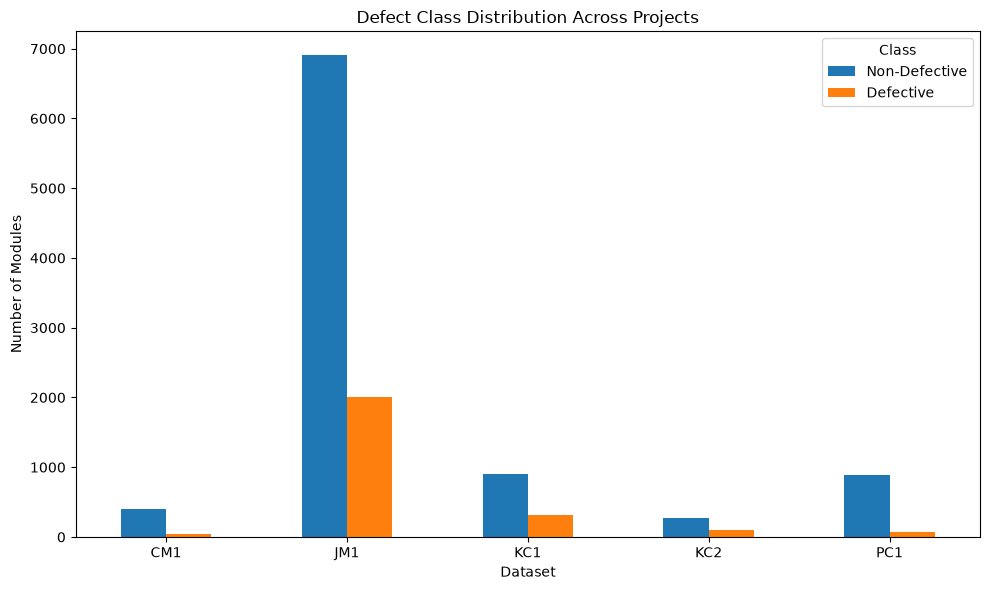

In [27]:
plot_data = class_summary.set_index("Dataset")[
    ["Non-Defective", "Defective"]
]

ax = plot_data.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Defect Class Distribution Across Projects")
plt.xlabel("Dataset")
plt.ylabel("Number of Modules")
plt.xticks(rotation=0)
plt.legend(title="Class")
plt.tight_layout()
plt.show()

# Step 22 — Feature distribution analysis

In [28]:
skewness_results = []

for name, df in datasets.items():

    X = df.drop(columns=["defects"])

    skewness = X.skew()

    for feature, value in skewness.items():

        skewness_results.append({
            "Dataset": name,
            "Feature": feature,
            "Skewness": round(value, 3),
            "Absolute Skewness":
                round(abs(value), 3)
        })

skewness_df = pd.DataFrame(skewness_results)

display(
    skewness_df.sort_values(
        "Absolute Skewness",
        ascending=False
    )
)

,Dataset,Feature,Skewness,Absolute Skewness
30,JM1,e,41.855,41.855
32,JM1,t,41.855,41.855
36,JM1,locCodeAndComment,20.435,20.435
24,JM1,iv(g),19.910,19.910
95,PC1,t,17.253,17.253
...,...,...,...,...
50,KC1,i,1.799,1.799
49,KC1,d,1.620,1.620
16,CM1,uniq_Op,1.585,1.585
79,KC2,uniq_Op,0.819,0.819


# Step 23 — Distribution visualisation

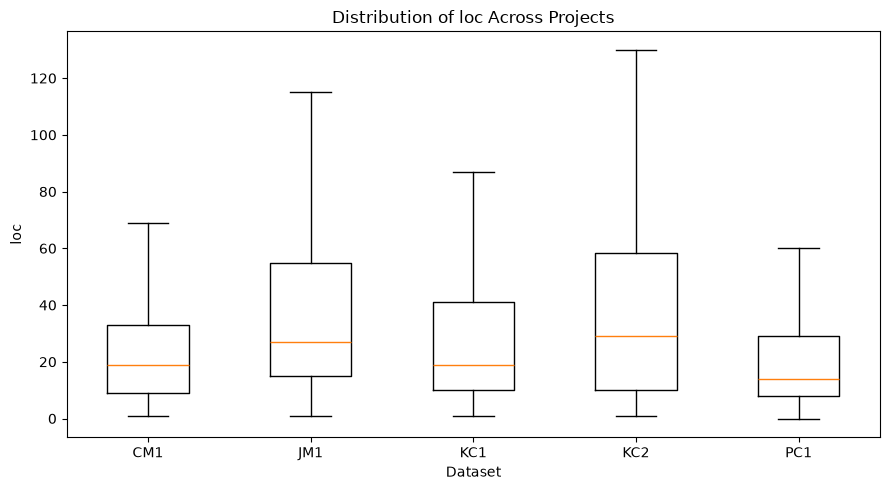

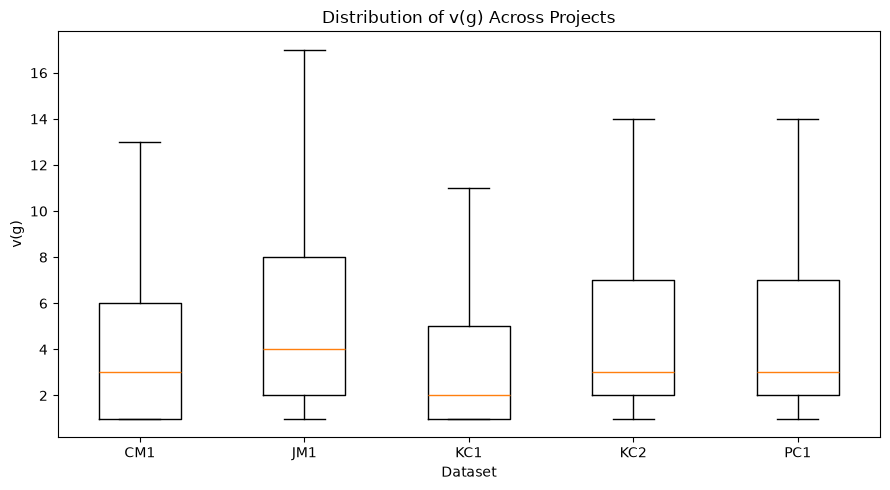

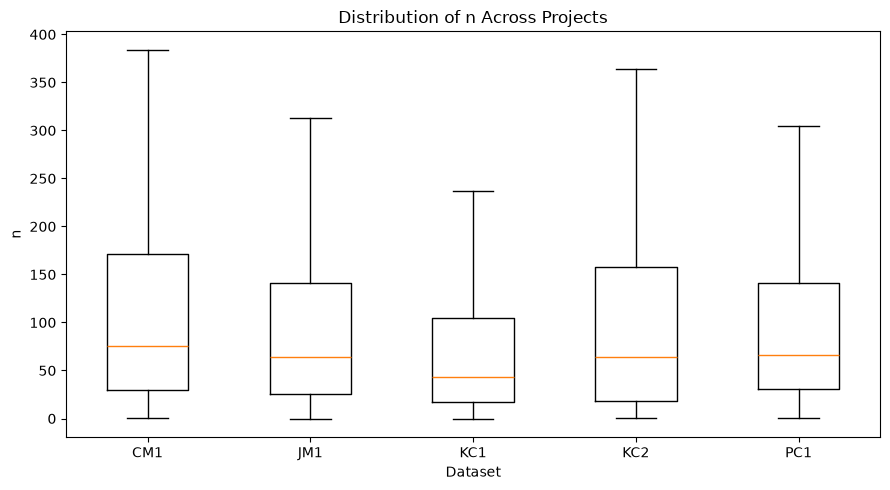

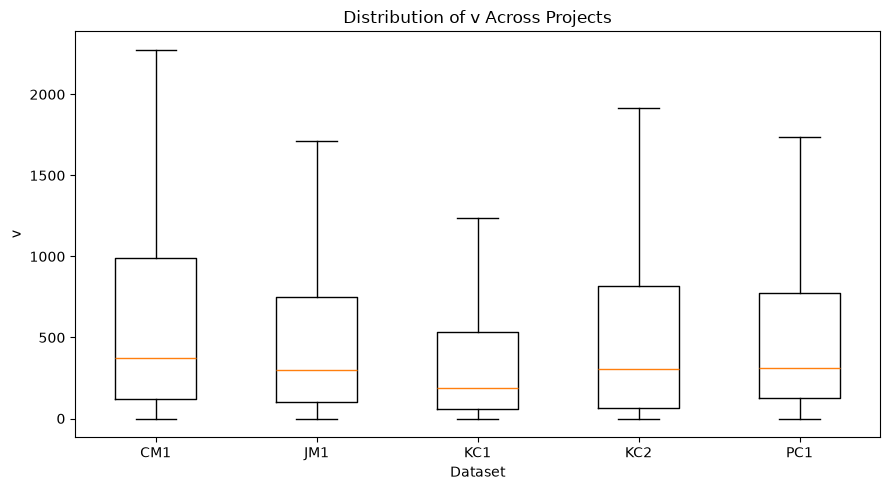

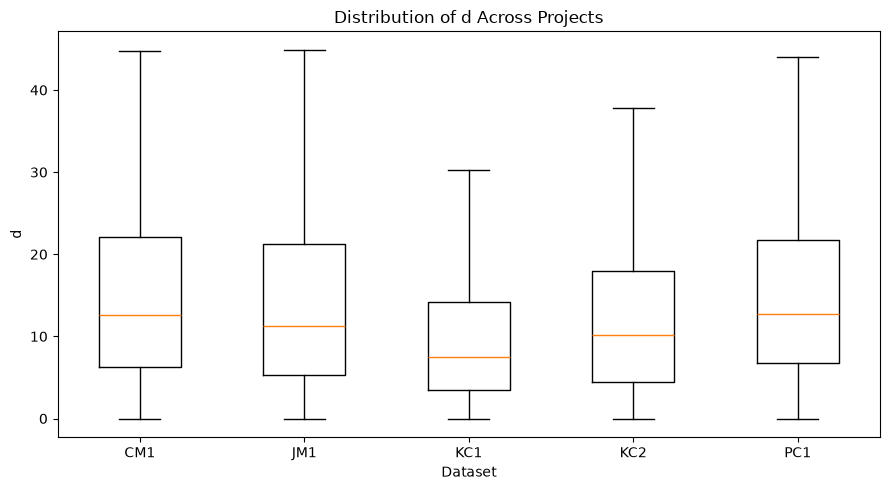

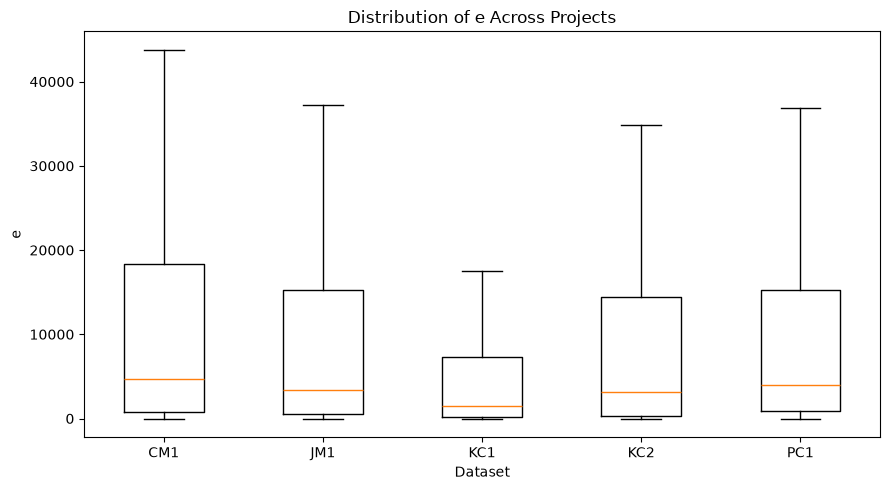

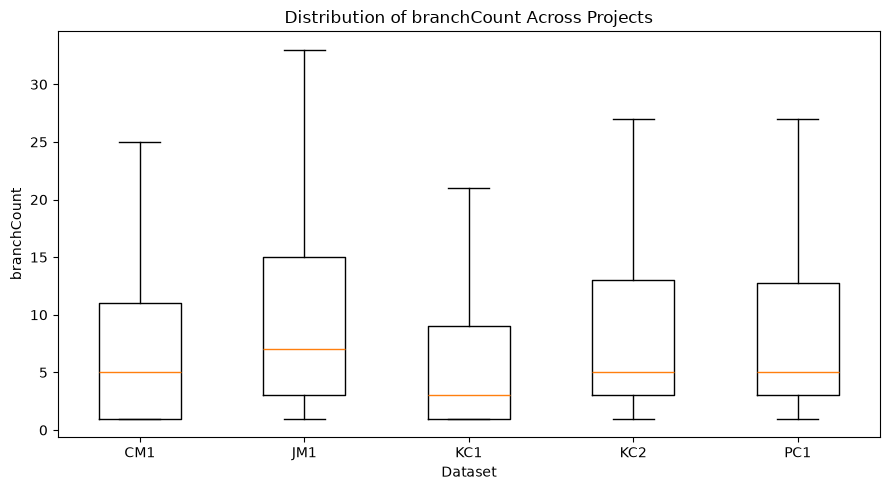

In [29]:
selected_features = [
    "loc",
    "v(g)",
    "n",
    "v",
    "d",
    "e",
    "branchCount"
]

for feature in selected_features:

    plot_data = [
        datasets[name][feature]
        for name in datasets
    ]

    plt.figure(figsize=(9, 5))

    plt.boxplot(
        plot_data,
        tick_labels=list(datasets.keys()),
        showfliers=False
    )

    plt.title(
        f"Distribution of {feature} Across Projects"
    )

    plt.xlabel("Dataset")
    plt.ylabel(feature)

    plt.tight_layout()
    plt.show()

# Step 24 — Correlation analysis

In [30]:
high_correlation_results = []

for name, df in datasets.items():

    X = df.drop(columns=["defects"])

    corr_matrix = X.corr()

    for i in range(len(corr_matrix.columns)):

        for j in range(i):

            correlation = corr_matrix.iloc[i, j]

            if abs(correlation) > 0.90:

                high_correlation_results.append({
                    "Dataset": name,
                    "Feature 1":
                        corr_matrix.columns[i],
                    "Feature 2":
                        corr_matrix.columns[j],
                    "Correlation":
                        round(correlation, 3)
                })

high_corr_df = pd.DataFrame(
    high_correlation_results
)

display(high_corr_df)

,Dataset,Feature 1,Feature 2,Correlation
0,CM1,v(g),loc,0.942
1,CM1,iv(g),loc,0.918
2,CM1,iv(g),v(g),0.930
3,CM1,n,loc,0.939
4,CM1,n,v(g),0.905
...,...,...,...,...
227,PC1,total_Opnd,v,0.976
228,PC1,total_Opnd,b,0.970
229,PC1,total_Opnd,lOCode,0.906
230,PC1,total_Opnd,total_Op,0.986


# Step 25 — Correlation heatmaps

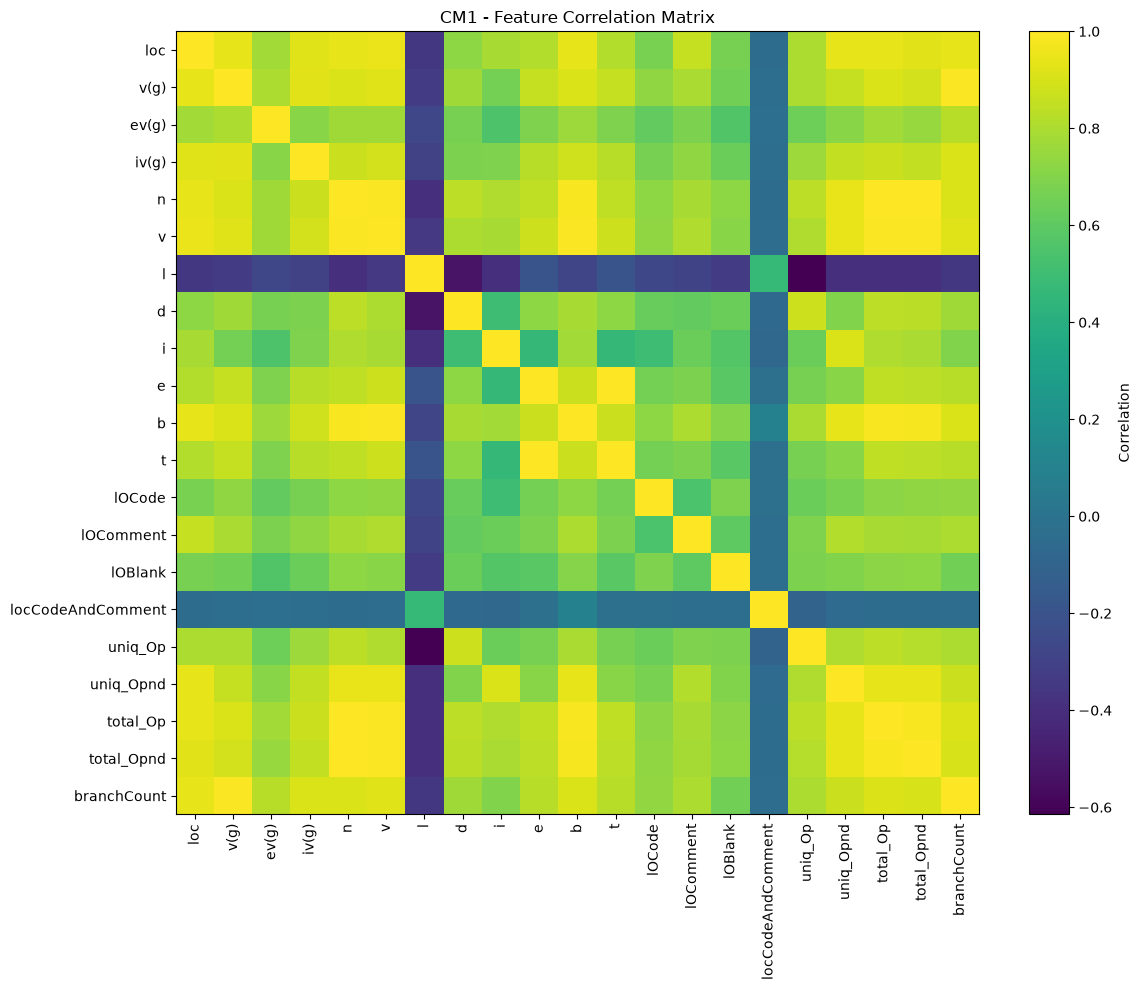

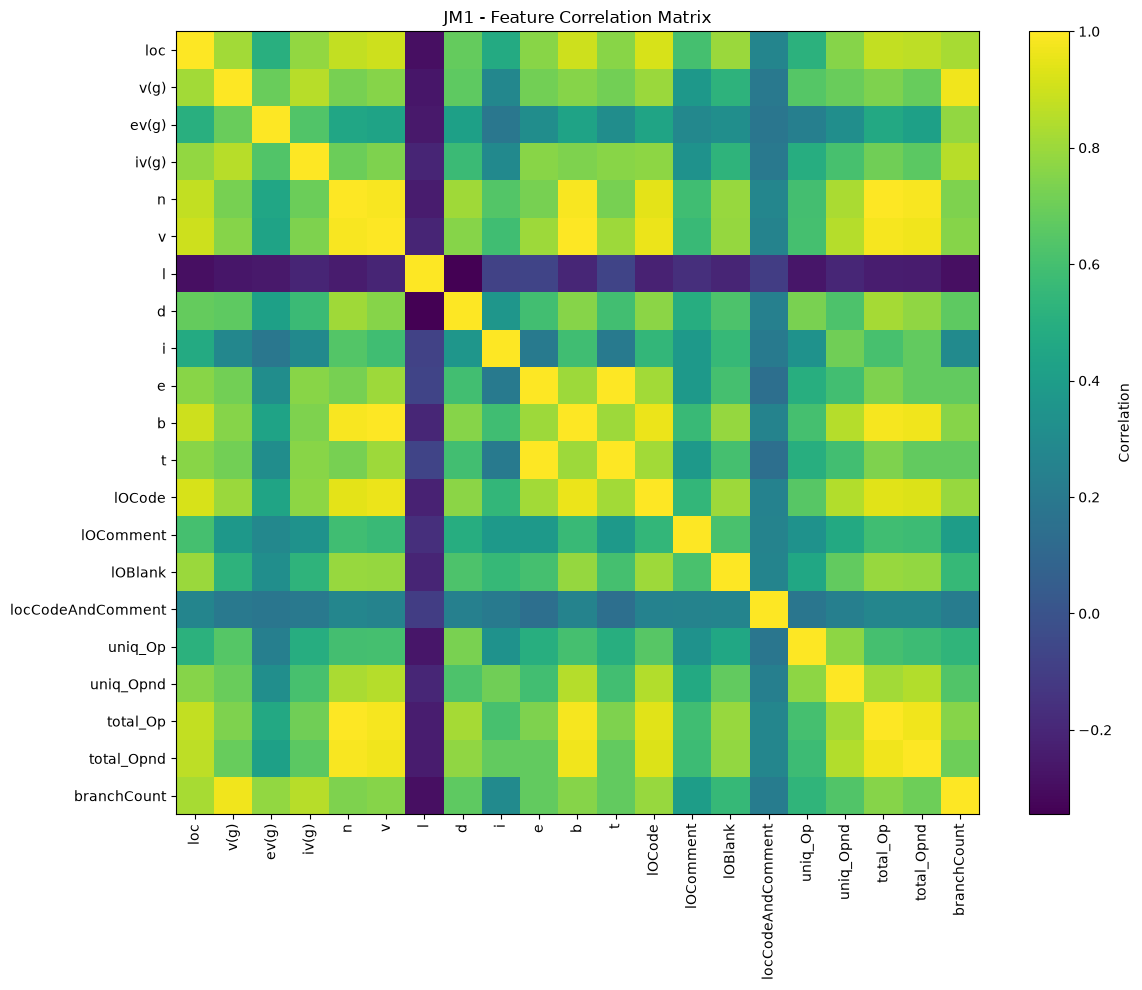

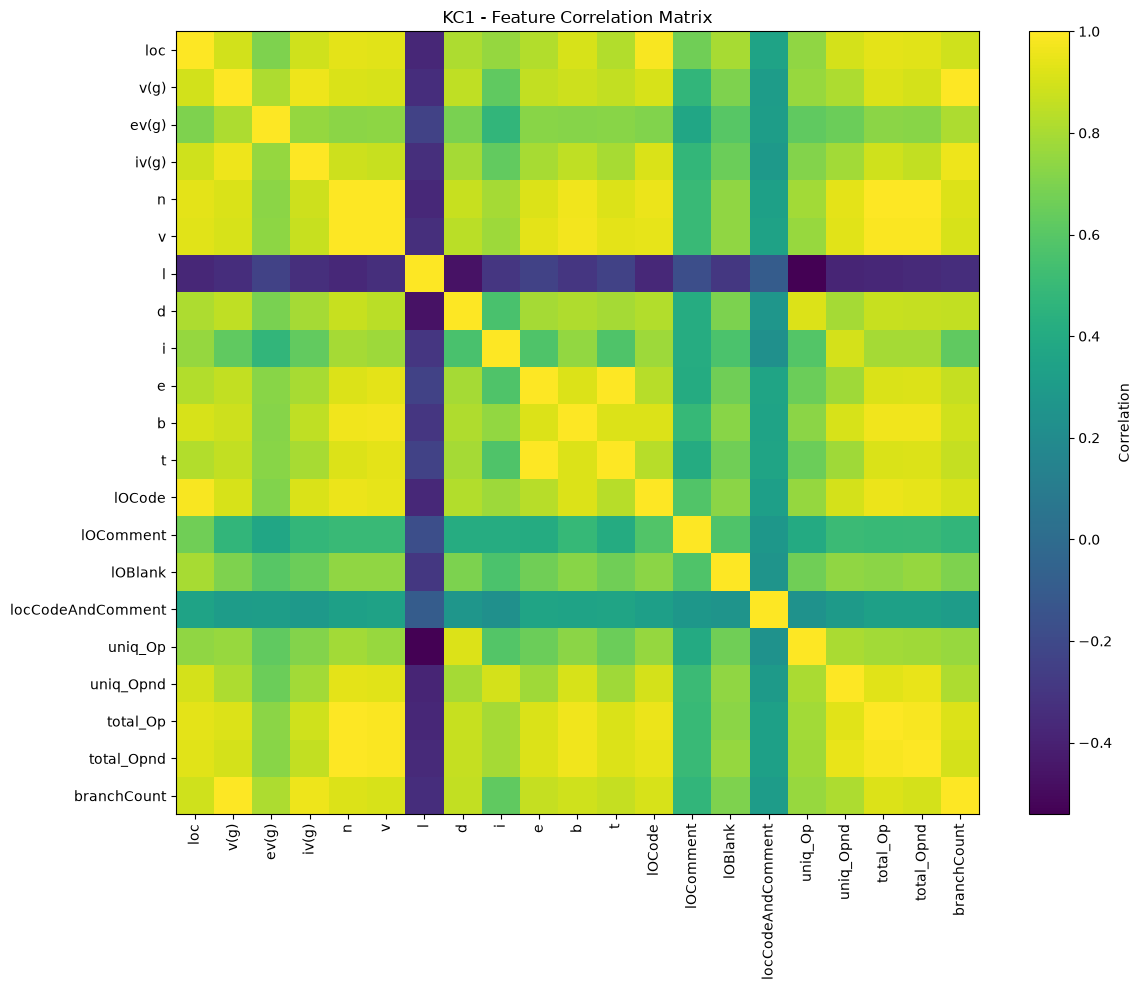

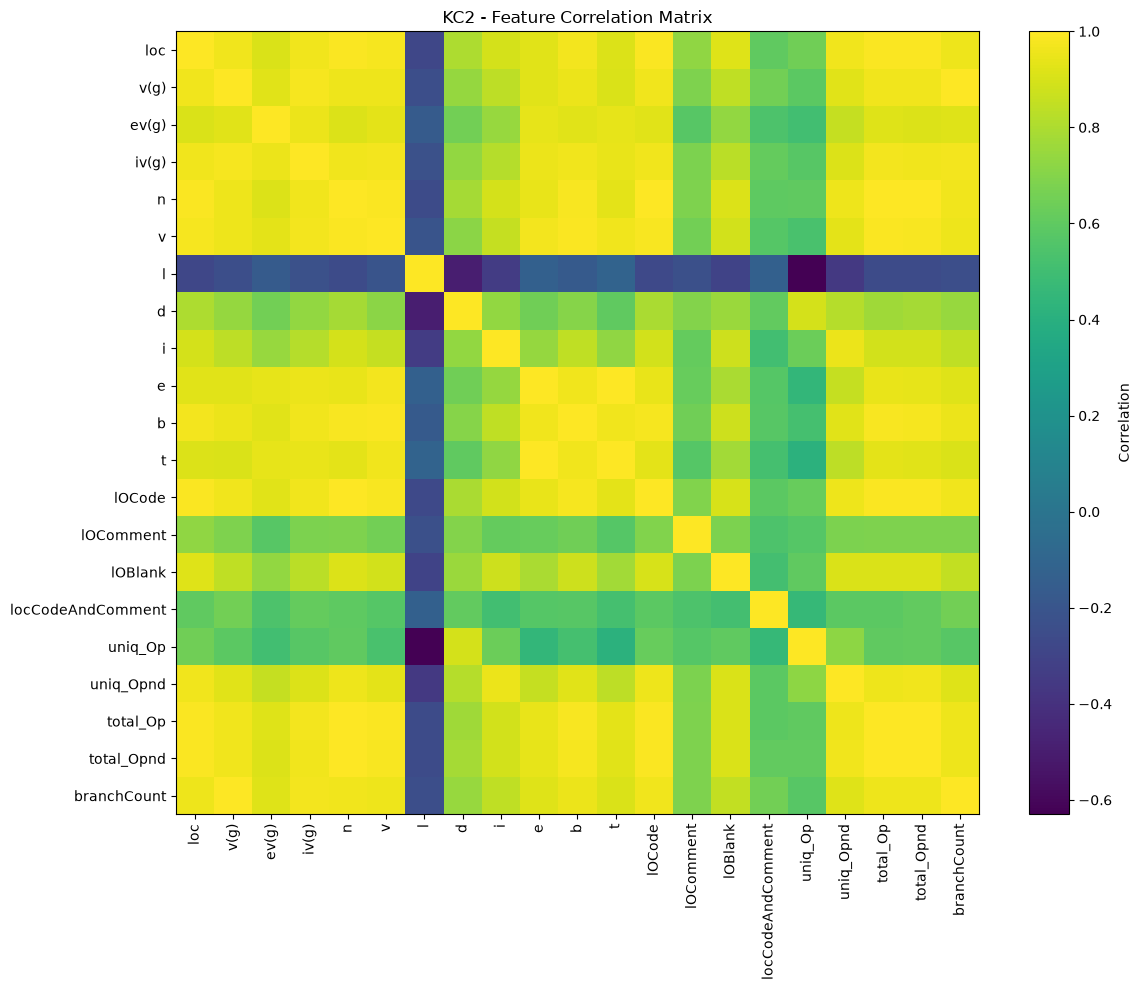

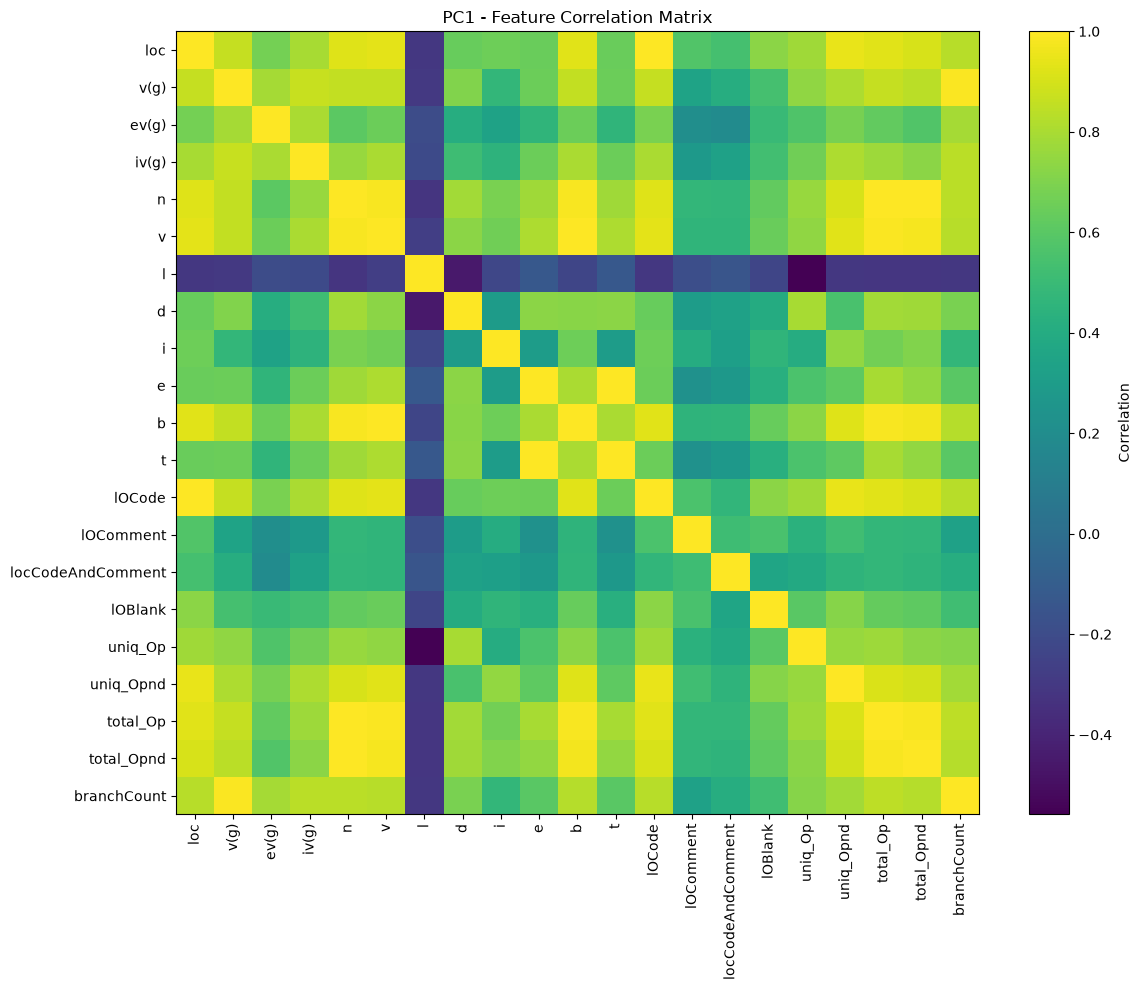

In [31]:
for name, df in datasets.items():

    X = df.drop(columns=["defects"])

    corr_matrix = X.corr()

    plt.figure(figsize=(12, 10))

    plt.imshow(
        corr_matrix,
        aspect="auto"
    )

    plt.colorbar(label="Correlation")

    plt.xticks(
        range(len(corr_matrix.columns)),
        corr_matrix.columns,
        rotation=90
    )

    plt.yticks(
        range(len(corr_matrix.columns)),
        corr_matrix.columns
    )

    plt.title(
        f"{name} - Feature Correlation Matrix"
    )

    plt.tight_layout()
    plt.show()

# Step 26 — Final Data Quality Summary
This section summarises the main data-quality characteristics of each
project after cleaning and schema standardisation. The summary provides
a consolidated record of the datasets used in subsequent experiments.

In [32]:
final_summary = []

for name, df in datasets.items():

    total = len(df)
    defective = int(df["defects"].sum())
    non_defective = total - defective

    X = df.drop(columns=["defects"])

    zero_variance = (X.var() == 0).sum()

    final_summary.append({
        "Dataset": name,
        "Final Rows": total,
        "Predictors": X.shape[1],
        "Missing Values": df.isnull().sum().sum(),
        "Duplicates": df.duplicated().sum(),
        "Zero-Variance Features": zero_variance,
        "Non-Defective": non_defective,
        "Defective": defective,
        "Defect Rate (%)": round(
            defective / total * 100, 2
        )
    })

final_summary = pd.DataFrame(final_summary)

display(final_summary)

,Dataset,Final Rows,Predictors,Missing Values,Duplicates,Zero-Variance Features,Non-Defective,Defective,Defect Rate (%)
0,CM1,442,21,0,0,0,394,48,10.86
1,JM1,8908,21,0,0,0,6904,2004,22.50
2,KC1,1212,21,0,0,0,897,315,25.99
3,KC2,375,21,0,0,0,270,105,28.00
4,PC1,954,21,0,0,0,884,70,7.34


## Check for impossible fractional values in count-based metrics

In [33]:
print("FRACTIONAL VALUE ANOMALY CHECK")
print("=" * 70)

anomaly_summary = []

for name, df in datasets.items():

    anomaly_mask = df["loc"] % 1 != 0
    anomaly_count = anomaly_mask.sum()

    anomaly_summary.append({
        "Dataset": name,
        "Anomalous Rows": anomaly_count
    })

    if anomaly_count > 0:
        print(f"\n{name}: found {anomaly_count} row(s) with a fractional 'loc' value")
        display(df[anomaly_mask])

anomaly_summary = pd.DataFrame(anomaly_summary)
display(anomaly_summary)

FRACTIONAL VALUE ANOMALY CHECK

CM1: found 1 row(s) with a fractional 'loc' value


,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,...,lOCode,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,defects
0,1.1,1.4,1.4,1.4,1.3,1.3,1.3,1.3,1.3,1.3,...,2,2,2,2,1.2,1.2,1.2,1.2,1.4,False



JM1: found 1 row(s) with a fractional 'loc' value


,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,...,lOCode,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,defects
0,1.1,1.4,1.4,1.4,1.3,1.3,1.3,1.3,1.3,1.3,...,2,2,2,2,1.2,1.2,1.2,1.2,1.4,False



KC1: found 1 row(s) with a fractional 'loc' value


...


KC2: found 1 row(s) with a fractional 'loc' value


,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,...,lOCode,lOComment,lOBlank,locCodeAndComment,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,defects
0,1.1,1.4,1.4,1.4,1.3,1.3,1.3,1.3,1.3,1.3,...,2,2,2,2,1.2,1.2,1.2,1.2,1.4,False



PC1: found 1 row(s) with a fractional 'loc' value


,loc,v(g),ev(g),iv(g),n,v,l,d,i,e,...,lOCode,lOComment,locCodeAndComment,lOBlank,uniq_Op,uniq_Opnd,total_Op,total_Opnd,branchCount,defects
0,1.1,1.4,1.4,1.4,1.3,1.3,1.3,1.3,1.3,1.3,...,2,2,2,2,1.2,1.2,1.2,1.2,1.4,False


,Dataset,Anomalous Rows
0,CM1,1
1,JM1,1
2,KC1,1
3,KC2,1
4,PC1,1


## Remove the anomalous row(s)

In [34]:
print("REMOVING FRACTIONAL-VALUE ANOMALIES")
print("=" * 70)

artefact_removal_summary = []

for name, df in datasets.items():

    rows_before = len(df)

    anomaly_mask = df["loc"] % 1 != 0
    datasets[name] = df.loc[~anomaly_mask].reset_index(drop=True)

    rows_after = len(datasets[name])

    artefact_removal_summary.append({
        "Dataset": name,
        "Rows Before": rows_before,
        "Anomalies Removed": rows_before - rows_after,
        "Rows After": rows_after
    })

artefact_removal_summary = pd.DataFrame(artefact_removal_summary)
display(artefact_removal_summary)

REMOVING FRACTIONAL-VALUE ANOMALIES


,Dataset,Rows Before,Anomalies Removed,Rows After
0,CM1,442,1,441
1,JM1,8908,1,8907
2,KC1,1212,1,1211
3,KC2,375,1,374
4,PC1,954,1,953


# Step 27 — Save the cleaned datasets

In [ ]:
from pathlib import Path

cleaned_path = ROOT / "data" / "processed"
cleaned_path.mkdir(parents=True, exist_ok=True)

for name, df in datasets.items():
    output_file = cleaned_path / f"{name.lower()}_cleaned.csv"
    df.to_csv(output_file, index=False)
    print(f"{name} saved to: {output_file}")

CM1 saved to: cm1_cleaned.csv
JM1 saved to: jm1_cleaned.csv
KC1 saved to: kc1_cleaned.csv
KC2 saved to: kc2_cleaned.csv
PC1 saved to: pc1_cleaned.csv
